#### Workflow

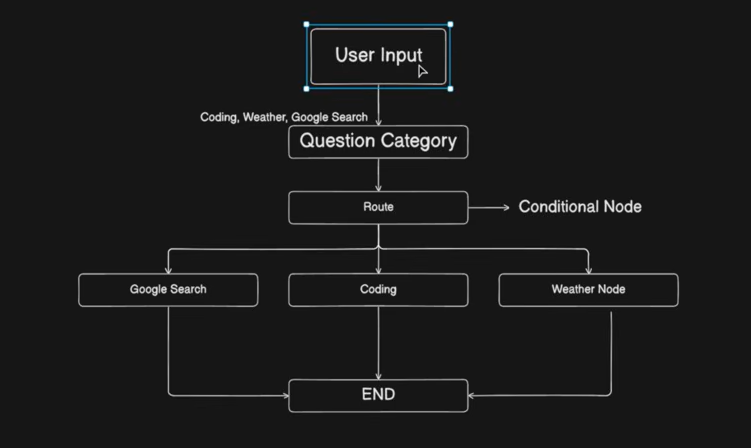

In [23]:
# Create State clases -> Find question category -> Condational Node (Route) -> Other 3 nodes
# -> create Graph

In [24]:
# load env ver
from dotenv import load_dotenv
load_dotenv()

True

In [25]:
# all imports
from langchain_anthropic import ChatAnthropic
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel, Field
from typing import Literal

# for agents
from langchain_community.utilities import GoogleSerperAPIWrapper
from langchain.agents import create_agent
from langchain.tools import tool


In [26]:
# state
# 1st of all we have to create a state
# what we have to store in state
# our state class include: question -> question category -> answer
class FlowState(BaseModel):
    question : str = Field(description="User will ask question")
    category : Literal["coding", "google_search", "weather"] = Field(default="google_search")
    answer : str = Field(default="")

In [27]:
# 2nd state
class QuestionCategory(BaseModel):
    category : Literal["coding", "google_search", "weather"] = Field(default="google_search", 
                                                                     description= "Category of Question.")

In [28]:
llm = ChatAnthropic(model="claude-opus-5")

In [42]:
# get question's category
def find_question_cat(state: FlowState) -> FlowState:
    str_llm = llm.with_structured_output(QuestionCategory)
    res = str_llm.invoke(f"You will find the question category: {state.question}. \
                         If you are not sure return google_search default category.")
    state.category = res.category
    return state

In [43]:
# just checking wether we are getting TRUE question category.
flow = FlowState(question="weather in Rouen?")
find_question_cat(flow)

FlowState(question='weather in Rouen?', category='weather', answer='')

In [33]:
# Conditional NODE
def route(state: FlowState) -> Literal["coding", "google_search", "weather"]:
    return state.category

In [35]:
# AGENTS
search = GoogleSerperAPIWrapper()
google_search_agent = create_agent(
    model=llm,
    tools=[search.run],
    system_prompt="You will seach from google and answer the questions."
)

# weather agent -- manual, later will implement API like google serper.
@tool
def get_weather(city:str):
    """It provide real time weather details for any city"""
    return f"The temptarure of {city} is -1C."

weather_agent = create_agent(
    model=llm,
    tools=[get_weather],
    system_prompt="You are a agent and can provide real time weather details."
)


In [37]:
# NODES (remaining 3)
# 1. google_search, 2. weather 3. coding

# we are using 'llm' for following google search
def coding_node(state:FlowState) -> FlowState:
    res = llm.invoke(f"You are a coding expert: {state.question}")
    state.answer = res.content
    return state

# we are using 'agents' for both of following
def google_search_node(state:FlowState) -> FlowState:
    res = google_search_agent.invoke(
        {"messages":[{"role":"user", "content": state.question}]}
    )
    state.answer = res["messages"][-1].content
    return state
   

def weather_node(state:FlowState) -> FlowState:
    res = weather_agent.invoke(
        {"messages":[{"role":"user", "content":state.question}]}
    )
    state.answer = res["messages"][-1].content
    return state

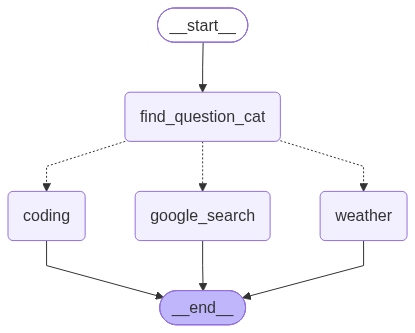

In [38]:
# GRAPH

graph = StateGraph(FlowState)

# name of the parameters must match with above declared litral
# otherwise will throug error.
graph.add_node("find_question_cat", find_question_cat)
graph.add_node("google_search", google_search_node)
graph.add_node("weather", weather_node)
graph.add_node("coding", coding_node)

graph.add_edge(START, "find_question_cat")
graph.add_conditional_edges("find_question_cat", route)
graph.add_edge("google_search", END)
graph.add_edge("weather", END)
graph.add_edge("coding", END)

graph = graph.compile()
graph

In [39]:
res = graph.invoke({"question":"Weather of Rouen?"})
res

{'question': 'Weather of Rouen?',
 'category': 'weather',
 'answer': 'The current temperature in Rouen is **‑1\u202f°C**. Let me know if you’d like more details such as humidity, wind speed, or a forecast!'}